# 03 — Conformal prediction v2: image-level conformal risk control

Post-hoc analysis on the cached test logits (CPU only, no GPU needed).
Model: CBAM + Dice-BCE, TN3K test set (614 images).

Inputs: the logits from the release (or notebook 01, Section 8B) and the ground-truth masks `test_masks.npy`, built from TN3K by notebook 01, Section 8A (CPU).

**Map of the notebook**
0. Setup and data loading (sanity check against Table 1)
1. Per-image morphological scores (`k_out`, `k_in`)
2. Per-image metadata (number of nodules, predicted and true size)
3. Repeated calibration/test splits and strict containment (image-level split conformal)
4. Conformal risk control (CRC): loss curves, choice of lambda/mu, 200 repeated splits (Table 4)
5. Mondrian-CRC by predicted-area strata (Table 5), comparison with the single-lambda CRC by stratum (Table 4), robustness checks (Table 6)
6. Figure 2: inner mask and uncertainty band for one image per stratum (needs the TN3K test images; saved in `figures/`)

**Conventions**
- The exchangeable unit is the **image**, not the pixel.
- Outer set O = prediction dilated by `lambda` pixels. Inner set I = prediction eroded by `mu` pixels. In the code `side` is `"out"` or `"in"`.
- Guarantees hold **in expectation over calibration draws**: single splits can fall on either side of the target.
- Next to each check cell the expected values (seed 42, or 200-split means) are written as comments.

# 0. Setup and data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path
from scipy.special import expit                      # sigmoid
from scipy.ndimage import label, distance_transform_edt

# Paths: repository root (works from the repo root or from notebooks/), cached logits, outputs
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROJECT_ROOT = Path(os.environ.get("PROJECT_ROOT", REPO_ROOT))
CACHE = Path(os.environ.get("THYROID_CACHE", PROJECT_ROOT / "cache" / "logits"))
FIG_DIR = REPO_ROOT / "figures"
TN3K_IMG = PROJECT_ROOT / "data" / "Thyroid Dataset" / "tn3k" / "test-image"   # only for the figures
MODEL = "CBAM_DiceBCE"

masks = np.load(CACHE / "test_masks.npy").astype(bool)          # (614, 256, 256)
names = (CACHE / "test_names.txt").read_text().splitlines()
probs = expit(np.load(CACHE / f"test_{MODEL}.npy"))              # (614, 256, 256)
preds = probs > 0.5                                              # binary prediction

# Sanity check: must match Table 1 (CBAM + Dice-BCE -> 89.60)
dice_g = 2 * (preds & masks).sum() / (preds.sum() + masks.sum())
print(masks.shape, len(names), f"Dice_g = {100 * dice_g:.2f}")

(614, 256, 256) 614 Dice_g = 89.60


# 1. Per-image morphological scores

For each image we want the minimal radius k such that:
- **outer**: the prediction dilated by k contains the whole ground truth,
  $k_{out} = \max_{v \in Y} d(v, \hat Y)$
- **inner**: the prediction eroded by k lies inside the ground truth,
  $k_{in} = \max_{v \in \hat Y \setminus Y} d(v, \hat Y^c)$, and $k_{in} = 0$ if there are no false positives.

`distance_transform_edt(x)` gives, for every non-zero pixel of `x`, the Euclidean distance to the nearest zero pixel.

Edge case: if the model predicts nothing, `k_out = inf` (no radius can cover the nodule) and `k_in = 0` (no false positives). In this test set no prediction is empty.

In [2]:
# Toy example: a 3x3 predicted square; distance of every pixel from the prediction
toy = np.zeros((7,7,), dtype=bool)
toy[2:5, 2:5] = True

print(toy.astype(int))
print(distance_transform_edt(~toy).round(2))

# Empty-prediction case (all-True input): scipy returns finite, misleading values -> handled with np.inf below
print(distance_transform_edt(np.ones((5,5), dtype=bool)))
print(distance_transform_edt(np.ones((5,5), dtype=bool)).min())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 1 1 1 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]
[[2.83 2.24 2.   2.   2.   2.24 2.83]
 [2.24 1.41 1.   1.   1.   1.41 2.24]
 [2.   1.   0.   0.   0.   1.   2.  ]
 [2.   1.   0.   0.   0.   1.   2.  ]
 [2.   1.   0.   0.   0.   1.   2.  ]
 [2.24 1.41 1.   1.   1.   1.41 2.24]
 [2.83 2.24 2.   2.   2.   2.24 2.83]]
[[1.         1.41421356 2.23606798 3.16227766 4.12310563]
 [2.         2.23606798 2.82842712 3.60555128 4.47213595]
 [3.         3.16227766 3.60555128 4.24264069 5.        ]
 [4.         4.12310563 4.47213595 5.         5.65685425]
 [5.         5.09901951 5.38516481 5.83095189 6.40312424]]
1.0


In [3]:
def morph_scores(pred: np.ndarray, gt: np.ndarray) -> tuple[float, float]:
    """Minimal dilation radius covering gt (k_out) and minimal erosion
    radius making pred fall inside gt (k_in), via Euclidean distance transform.

    Args:
        pred: boolean (H, W) predicted mask
        gt:   boolean (H, W) ground-truth mask
    Returns:
        (k_out, k_in)
    """
    # Outer score: farthest ground-truth pixel from the prediction
    if not pred.any():
        k_out = np.inf                                 # empty prediction: no radius is enough
    else:
        d_to_pred = distance_transform_edt(~pred)      # distance of every pixel from the prediction
        k_out = d_to_pred[gt].max()

    # Inner score: deepest false-positive pixel inside the prediction
    d_to_out = distance_transform_edt(pred)            # depth of every predicted pixel (distance from the background)
    fp = pred & ~gt                                    # false-positive pixels
    if fp.any():
        k_in = d_to_out[fp].max()
    else:
        k_in = 0.0                                     # no false positives

    return (k_out, k_in)

In [4]:
print(morph_scores(preds[0], masks[0]))                # expected (3.61, 4.24)

(np.float64(3.605551275463989), np.float64(4.242640687119285))


In [5]:
# One row per image: k_out and k_in
rows = []
for i in range(len(preds)):
    k_out, k_in = morph_scores(preds[i], masks[i])
    rows.append({"idx" : i, "name" : names[i], "k_out" : k_out, "k_in" : k_in})
scores = pd.DataFrame(rows)

In [6]:
print(scores.shape)                                    # expected (614, 4)
scores.describe()

(614, 4)


,idx,k_out,k_in
count,614.000000,614.000000,614.000000
mean,306.500000,11.814751,9.487201
std,177.390811,20.099579,9.594445
min,0.000000,0.000000,0.000000
25%,153.250000,2.828427,4.000000
50%,306.500000,5.000000,6.324555
75%,459.750000,11.000000,10.954163
max,613.000000,142.555252,79.101201


# 2. Per-image metadata

Columns added to `scores` and arrays used later:
- `n_nod`: number of connected components in the ground truth (used only to stratify the calibration/test split).
- `pred_area`: number of predicted pixels. It is known at test time, so it is a legitimate stratification variable for Mondrian-CRC. The tertile edges computed here (all images) are only descriptive: inside the Mondrian functions the edges are recomputed on the calibration set of each split.
- `true_area`, `true_group`, `multi`: built from the ground truth, **only for evaluation** (never used to choose lambda or mu).

In [7]:
scores["n_nod"] = [label(m)[1] for m in masks]         # connected components of the ground truth

# Predicted-area strata (descriptive; edges are recomputed per split in the Mondrian functions)
scores["pred_area"] = preds.sum(axis = (1,2))
q_threshold = np.quantile(scores["pred_area"], [1/3, 2/3])
scores["group"] = np.digitize(scores["pred_area"], q_threshold)    # 0 = small, 1 = medium, 2 = large
pred_area = scores["pred_area"].values                 # array version, used by the Mondrian functions

# Evaluation-only labels (they use the ground truth)
true_area = masks.sum(axis=(1, 2))
true_group = np.digitize(true_area, np.quantile(true_area, [1/3, 2/3]))
multi = (scores["n_nod"].values > 1).astype(int)       # 0 = single nodule, 1 = multiple nodules

In [8]:
print(q_threshold)                                     # expected ~ [2611, 8545]
print(scores["group"].value_counts().sort_index())     # expected 205 / 204 / 205

[2610.66666667 8545.        ]
group
0    205
1    204
2    205
Name: count, dtype: int64


# 3. Repeated calibration/test splits and rigorous containment

Image-level split conformal. For each image the score is `k_out` (or `k_in`); the threshold is the finite-sample quantile of the calibration scores, rank $k = \lceil (1-\alpha)(n+1) \rceil$. An image is "contained" when its score is $\le$ the threshold.
The calibration/test split is stratified by single vs multiple nodules (30% calibration) and repeated over 200 seeds.

In [9]:
def stratified_calibration_split(
    n_nod: list,
    calibration_split: float = 0.3,
    seed: int = 42
    ):
    """Random calibration/test split stratified by single vs multiple nodules.

    Args:
        n_nod: number of nodules of each image (indexable by position)
        calibration_split: fraction of each stratum assigned to calibration
        seed: random seed
    Returns:
        (cal_idx, test_idx): sorted lists of image indices
    """
    rng = np.random.default_rng(seed)
    groups = {"single": [],
              "multiple": []}

    for idx in range(len(n_nod)):
        if n_nod[idx] == 1:
            groups["single"].append(idx)
        else:
            groups["multiple"].append(idx)

    singles = np.array(groups["single"])
    multiples = np.array(groups["multiple"])

    rng.shuffle(singles)
    rng.shuffle(multiples)

    n_calibr_single = round(calibration_split * len(singles))
    n_calibr_multiple = round(calibration_split * len(multiples))

    cal_idx = np.concatenate([singles[:n_calibr_single], multiples[:n_calibr_multiple]])
    test_idx = np.concatenate([singles[n_calibr_single:], multiples[n_calibr_multiple:]])

    return (sorted(cal_idx), sorted(test_idx))

In [10]:
a, b = stratified_calibration_split(scores["n_nod"])
print(len(a), len(b))                                  # expected 184 430

184 430


In [11]:
def conformal_quantile(
    cal_scores: np.ndarray,
    alpha: float
) -> float:
    """k-th smallest calibration score, k = ceil((1 - alpha)(n + 1)); inf if k > n."""
    n = cal_scores.shape[0]
    k = int(np.ceil((1 - alpha)*(n + 1)))
    if k>n:
        return np.inf
    else:
        return np.sort(cal_scores)[k-1]

In [12]:
# Single split (seed 42): threshold on k_out at alpha = 0.05
cal, test = stratified_calibration_split(scores["n_nod"])
q_out = conformal_quantile(scores["k_out"].values[cal], 0.05)
print(q_out)                                           # expected 39.81

39.81205847478876


In [13]:
# 200 repeated splits. alpha is the level PER SIDE:
#   alpha = 0.05  -> joint containment ~0.905 (union bound: only >= 0.90)
#   alpha = 0.025 -> joint containment ~0.957 (>= 0.95 by Bonferroni)
results = []
alpha = 0.025
for i in range(200):
    cal, test = stratified_calibration_split(scores["n_nod"], seed=i)

    q_out = conformal_quantile(scores["k_out"].values[cal], alpha)
    q_in = conformal_quantile(scores["k_in"].values[cal], alpha)

    cover_out = (scores["k_out"].values[test] <= q_out).mean()
    cover_in = (scores["k_in"].values[test] <= q_in).mean()

    both = ((scores["k_out"].values[test] <= q_out) & (scores["k_in"].values[test] <= q_in)).mean()

    results.append({"seed" : i, "q_out" : q_out, "containment_out" : cover_out, "q_in" : q_in, "containment_in" : cover_in, "containment_tot" : both})

res_df = pd.DataFrame(results)
print(res_df.describe())
print((res_df["containment_out"] < 0.95).mean())      # fraction of splits below 0.95 (alpha=0.05: out 0.425, in 0.415)
print((res_df["containment_in"] < 0.95).mean())
print((res_df["containment_tot"] < 0.95).mean())      # alpha=0.05: 0.975; alpha=0.025: 0.265

             seed       q_out  containment_out        q_in  containment_in  \
count  200.000000  200.000000       200.000000  200.000000      200.000000   
mean    99.500000   92.899799         0.979523   40.497430        0.977849   
std     57.879185   13.525236         0.012822    4.771475        0.013674   
min      0.000000   35.468296         0.902326   29.068884        0.930233   
25%     49.750000   87.091905         0.974419   37.947332        0.969767   
50%     99.500000   97.575612         0.981395   40.049969        0.979070   
75%    149.250000  102.489024         0.988372   44.000000        0.988372   
max    199.000000  116.811814         0.997674   53.000000        1.000000   

       containment_tot  
count       200.000000  
mean          0.957384  
std           0.016998  
min           0.883721  
25%           0.948837  
50%           0.958140  
75%           0.969767  
max           0.993023  
0.025
0.04
0.265


In [14]:
# Diagnostic: heavy tail of k_out (the reason why the outer band is so wide)
k = scores["k_out"].values
print(np.isinf(k).sum())                               # images with an empty prediction (expected 0)
print((k > 90).sum(), (k > 90).mean())                 # expected 14, 0.0228
print(np.percentile(k[np.isfinite(k)], [50, 90, 95, 97.5, 99]))    # expected ~ [5, 28, 48, 85, 106]

0
14 0.02280130293159609
[  5.          28.25943708  47.78286634  85.45141987 105.61      ]


# 4. Conformal risk control (CRC)

"Nodule fully contained" is a 0/1 loss and forces a huge band because of a few missed nodules. CRC replaces it with a loss in [0, 1] that is **non-increasing** in the radius:
- outer: $L_{out}(\lambda)$ = fraction of ground-truth pixels left outside the prediction dilated by $\lambda$;
- inner: $L_{in}(\mu)$ = fraction of the *original* prediction that is false positive and survives an erosion by $\mu$ (fixed denominator, so it is monotone).

Rule: on the calibration set choose the smallest radius with $\frac{n}{n+1}\hat R(\lambda) + \frac{1}{n+1} \le \delta$.
Guarantee: $E[L(\hat\lambda)] \le \delta$ on a new image, in expectation over calibration draws. The observed risk is about $\delta - 1/(n+1)$.

## 4.1 Functions for the loss curves

In [15]:
def loss_curve_out(pred, gt, lambdas):
    """Fraction of GT pixels left outside the prediction dilated by each lambda."""
    if not pred.any():
        return np.ones(len(lambdas))                   # empty prediction: the whole nodule is missed for every lambda

    d_to_pred = distance_transform_edt(~pred)          # distance of every pixel from the prediction
    d_gt = d_to_pred[gt]                               # keep only the GT pixels -> 1D array

    # for each lambda, fraction of GT pixels farther than lambda
    curve = []
    for lam in lambdas:
        curve.append((d_gt > lam).mean())

    return np.array(curve)

In [16]:
def loss_curve_in(pred, gt, mus):
    """Fraction of the original prediction that is false positive and survives erosion by each mu."""
    if not pred.any():
        return np.zeros(len(mus))                      # empty prediction -> no false positives at all

    d_to_out = distance_transform_edt(pred)            # depth of every predicted pixel
    fp = pred & ~gt                                    # false-positive pixels
    d_fp = np.asarray(d_to_out[fp])                    # depths of the false positives only (1D array)
    n_pred = pred.sum()                                # size of the original prediction (fixed denominator)

    # for each mu, false positives deeper than mu / size of the prediction
    curve = []
    for mu in mus:
        curve.append((d_fp > mu).sum() / n_pred)

    return np.array(curve)

In [17]:
def crc_lambda(L_cal, delta, lambdas):
    """Smallest lambda whose corrected calibration risk is <= delta.

    Works for both sides: pass the outer loss matrix (lambda = dilation) or the inner one (mu = erosion).
    """
    n = L_cal.shape[0]
    risk = L_cal.mean(axis = 0)                        # mean loss over calibration images, one value per radius
    adj = (n/(n+1))*risk + 1/(n+1)                     # finite-sample correction
    ok = adj <= delta                                  # boolean array, True where the condition holds
    if not ok.any():
        return lambdas[-1]                             # no radius satisfies it -> return the largest one
    return (lambdas[ok][0])                            # first (smallest) radius where ok is True

## 4.2 Loss matrices and lambda/mu hat

In [18]:
lambdas = np.arange(0,201)                             # grid of radii in pixels (the value equals its index)

In [19]:
# Loss matrices: one row per image, one column per radius
L_mat = np.stack([loss_curve_out(preds[i], masks[i], lambdas) for i in range(len(masks))])
L_mat_in = np.stack([loss_curve_in(preds[i], masks[i], lambdas) for i in range(len(masks))])

In [20]:
print(L_mat.shape, L_mat.mean(axis=0)[[0, 5, 20, 50]])      # expected (614, 201) [0.1111 0.0565 0.0305 0.0160]
print(L_mat_in.shape, L_mat_in.mean(axis=0)[[0, 5, 20, 50]])  # expected (614, 201) [0.1531 0.0444 0.0051 0.0003]

# Consistency with the scores: the first radius with zero loss is ceil(k)
first_zero_in = (L_mat_in == 0).argmax(axis=1)
print((first_zero_in == np.ceil(scores["k_in"].values)).all())   # expected True

(614, 201) [0.11110105 0.05652344 0.03046157 0.01595433]
(614, 201) [0.15309513 0.04438037 0.00507693 0.00028138]
True


In [21]:
# Single split (seed 42), delta = 0.05
delta = 0.05
cal, test = stratified_calibration_split(scores["n_nod"], seed=42)
lam_hat = crc_lambda(L_mat[cal], delta, lambdas)
mu_hat = crc_lambda(L_mat_in[cal], delta, lambdas)
print(lam_hat)                                         # expected 5
print(L_mat[test, lam_hat].mean())                     # expected 0.0617 (above delta in this split: guarantee is in expectation)
print(mu_hat)                                          # expected 5
print(L_mat_in[test, mu_hat].mean())                   # expected 0.0454

5
0.06169717464725889
5
0.045376127768981436


## 4.3 CRC without stratification

One single lambda (and one mu) for all images, 200 repeated splits, three values of delta.
Expected at delta = 0.05: lambda 10.5 (sd 4.7), risk 0.0436, strict containment 0.70, 74.5% of splits with risk <= delta; mu 5.6, risk 0.0404.
`strict` = fraction of test images with loss exactly 0.

In [22]:
rows_out = []
rows_in = []

for delta in [0.05, 0.02, 0.01]:
    for i in range(200):
        cal, test = stratified_calibration_split(scores["n_nod"], seed=i)
        lam_hat = crc_lambda(L_mat[cal], delta, lambdas)
        risk_test = L_mat[test, lam_hat].mean()
        strict = (L_mat[test, lam_hat] == 0).mean()
        rows_out.append({
            "delta": delta,
            "seed": i,
            "lambda_min": lam_hat,
            "risk": risk_test,
            "strict": strict
        })
        mu_hat = crc_lambda(L_mat_in[cal], delta, lambdas)
        risk_test = L_mat_in[test, mu_hat].mean()
        strict = (L_mat_in[test, mu_hat] == 0).mean()
        rows_in.append({
            "delta": delta,
            "seed": i,
            "mu_min": mu_hat,
            "risk": risk_test,
            "strict": strict
        })

res_crc_out = pd.DataFrame(rows_out)
res_crc_in = pd.DataFrame(rows_in)
res_crc_out["risk_ok"] = res_crc_out["risk"] <= res_crc_out["delta"]
res_crc_in["risk_ok"] = res_crc_in["risk"] <= res_crc_in["delta"]

In [23]:
summary_out = res_crc_out.groupby("delta").agg(
    lambda_mean = ("lambda_min", "mean"),
    lambda_sd = ("lambda_min", "std"),
    risk_mean = ("risk", "mean"),
    strict_mean = ("strict", "mean"),
    frac_below_delta = ("risk_ok", "mean")
)
summary_in = res_crc_in.groupby("delta").agg(
    mu_mean = ("mu_min", "mean"),
    mu_sd = ("mu_min", "std"),
    risk_mean = ("risk", "mean"),
    strict_mean = ("strict", "mean"),
    frac_below_delta = ("risk_ok", "mean")
)

print(summary_out.round(4))
print(summary_in.round(4))

       lambda_mean  lambda_sd  risk_mean  strict_mean  frac_below_delta
delta                                                                  
0.01         95.93    20.5501     0.0056       0.9805             0.850
0.02         55.72    16.8780     0.0150       0.9503             0.760
0.05         10.47     4.6591     0.0436       0.6994             0.745
       mu_mean   mu_sd  risk_mean  strict_mean  frac_below_delta
delta                                                           
0.01    21.470  3.2375     0.0047       0.9022             0.955
0.02    12.735  1.8003     0.0139       0.7935             0.885
0.05     5.630  0.8525     0.0404       0.4517             0.950


# 5. Mondrian-CRC by predicted-area strata

The single-lambda CRC controls the risk only on average: noisy groups (small nodules) can be under-covered while easy ones are over-protected. Mondrian-CRC calibrates one radius **per stratum**.

Design rules:
- strata are defined by quantities **known at test time**: tertiles of the *predicted* area, with the edges computed on the calibration set of each split;
- ground-truth quantities (true area, single/multiple) are used **only to evaluate**, never to choose the radius;
- with about 61 calibration images per stratum the correction $1/(n_g+1) \approx 0.016$ makes delta below ~0.03 unusable (delta = 0.01 returns the largest radius everywhere).

## 5.1 Functions

In [24]:
def mondrian_crc(cal, test, delta, pred_area, L_mat, lambdas):
    """Group-wise CRC. Returns one row per test image; aggregation is done outside."""
    cal = np.asarray(cal); test = np.asarray(test)
    edges = np.quantile(pred_area[cal], [1/3, 2/3])    # tertile edges from the calibration set only
    group = np.digitize(pred_area, edges)              # predicted-area group of every image

    lam_by_group = {}
    for g in range(3):
        cal_g = cal[group[cal] == g]                   # calibration images of group g
        lam_by_group[g] = crc_lambda(L_mat[cal_g], delta, lambdas)

    lam_img = np.array([lam_by_group[g] for g in group[test]])   # radius assigned to each test image
    loss = L_mat[test, lam_img]                        # one loss per test image

    return pd.DataFrame({
        "img": test,
        "pred_group": group[test],
        "lam": lam_img,
        "loss": loss,
        "strict": loss == 0
    })

In [25]:
def marginal_crc_one_lambda(cal, test, delta, pred_area, L_mat, lambdas):
    """Single-lambda CRC, evaluated separately on each predicted-area group."""
    cal = np.asarray(cal)
    test = np.asarray(test)

    edges = np.quantile(pred_area[cal], [1/3, 2/3])    # tertile edges from the calibration set only
    group = np.digitize(pred_area, edges)              # predicted-area group of every image
    lam_g = crc_lambda(L_mat[cal], delta, lambdas)     # ONE lambda for all groups, from the whole calibration set
    out = []

    for g in range(3):
        test_g = test[group[test] == g]                # test images of group g
        risk_g = (L_mat[test_g, lam_g]).mean()         # mean test loss of group g at lam_g
        strict = (L_mat[test_g, lam_g] == 0).mean()
        out.append({"group": g, "n_test": len(test_g), "lam": lam_g, "risk": risk_g, "strict" : strict})
    return out

In [26]:
# Regression check (seed 42, delta = 0.05, outer side)
cal, test = stratified_calibration_split(scores["n_nod"], seed=42)
res = mondrian_crc(cal, test, 0.05, pred_area, L_mat, lambdas)
print(res.groupby("pred_group").agg(n_test=("loss", "size"), lam=("lam", "first"), risk=("loss", "mean")).round(4))
# expected: n_test 163 / 152 / 115, lam 35 / 5 / 3, risk 0.0469 / 0.0562 / 0.0387

            n_test  lam    risk
pred_group                     
0              163   35  0.0469
1              152    5  0.0562
2              115    3  0.0387


## 5.2 Mondrian-CRC, 200 repeated splits (outer and inner side)

`res_all` has one row per (side, delta, seed, test image). Summaries are computed in two steps: first the mean loss per split and group, then the mean over the 200 splits.
Expected at delta = 0.05 (outer): lambda 51.6 / 17.5 / 4.1 and risk 0.036 / 0.034 / 0.033 for small / medium / large; (inner): mu 5.5 / 9.4 / 6.8, risk 0.030 / 0.034 / 0.035.

In [27]:
dfs = []

for delta in [0.05, 0.04, 0.03, 0.02, 0.01]:          # 0.02 and 0.01 are degenerate/conservative with ~61 points per group
    for seed in range(200):
        cal, test = stratified_calibration_split(scores["n_nod"], seed=seed)
        for side, L in [("out", L_mat), ("in", L_mat_in)]:
            res = mondrian_crc(cal, test, delta, pred_area, L, lambdas)
            res["side"] = side
            res["delta"] = delta
            res["seed"] = seed
            dfs.append(res)

res_all = pd.concat(dfs, ignore_index=True)
print(res_all.shape)                                   # expected ~ (860000, 8)

(860000, 8)


In [28]:
per_split = res_all.groupby(["side", "delta", "seed", "pred_group"]).agg(
    lam=("lam", "first"),
    risk=("loss", "mean"),
    strict=("strict", "mean"),
).reset_index()
per_split["risk_ok"] = per_split["risk"] <= per_split["delta"]

summary = per_split.groupby(["side", "delta", "pred_group"]).agg(
    par_mean=("lam", "mean"),
    par_sd=("lam", "std"),
    risk_mean=("risk", "mean"),
    strict_mean=("strict", "mean"),
    frac_below_delta=("risk_ok", "mean"),
)
print(summary.round(4))

                       par_mean   par_sd  risk_mean  strict_mean  \
side delta pred_group                                              
in   0.01  0            200.000   0.0000     0.0000       1.0000   
           1            200.000   0.0000     0.0000       1.0000   
           2            200.000   0.0000     0.0000       1.0000   
     0.02  0             11.960   1.6035     0.0042       0.9202   
           1             22.535   2.8353     0.0047       0.9138   
           2             29.315   8.9074     0.0057       0.8667   
     0.03  0              8.265   1.0866     0.0130       0.8228   
           1             15.320   2.4978     0.0150       0.8355   
           2             15.640   4.6312     0.0154       0.7068   
     0.04  0              6.580   1.0290     0.0218       0.7216   
           1             11.805   2.3440     0.0246       0.7478   
           2             10.085   3.2358     0.0251       0.5550   
     0.05  0              5.495   0.8267     0.0

## 5.3 Comparison: single lambda evaluated by predicted-area group

Same strata, but one single radius for all images. Expected at delta = 0.05 (outer): risk 0.0746 / 0.0405 / 0.0155 for small / medium / large (only 7% of splits below delta for the small group), versus 0.036 / 0.034 / 0.033 with Mondrian-CRC.
Inner side: the medium group exceeds delta (0.0558, 34.5% of splits below delta).

In [29]:
rows_marg_out = []
rows_marg_in = []

for delta in [0.05, 0.02, 0.01]:
    for i in range(200):
        cal, test = stratified_calibration_split(scores["n_nod"], seed = i)
        out = marginal_crc_one_lambda(cal, test, delta, pred_area, L_mat, lambdas)
        inner = marginal_crc_one_lambda(cal, test, delta, pred_area, L_mat_in, lambdas)
        for r in out + inner:
            r["delta"] = delta
            r["seed"] = i
        rows_marg_out.extend(out)
        rows_marg_in.extend(inner)

res_marg_out = pd.DataFrame(rows_marg_out)
res_marg_in = pd.DataFrame(rows_marg_in)

res_marg_out["risk_ok"] = res_marg_out["risk"] <= res_marg_out["delta"]
res_marg_in["risk_ok"] = res_marg_in["risk"] <= res_marg_in["delta"]

summary_marg_out = res_marg_out.groupby(["delta", "group"]).agg(
    lambda_mean = ("lam", "mean"),
    lambda_sd = ("lam", "std"),
    risk_mean = ("risk", "mean"),
    strict_mean = ("strict", "mean"),
    frac_below_delta = ("risk_ok", "mean"),
)
summary_marg_in = res_marg_in.groupby(["delta", "group"]).agg(
    mu_mean = ("lam", "mean"),
    mu_sd = ("lam", "std"),
    risk_mean = ("risk", "mean"),
    strict_mean = ("strict", "mean"),
    frac_below_delta = ("risk_ok", "mean"),
)

print(summary_marg_out.round(4))
print(summary_marg_in.round(4))

             lambda_mean  lambda_sd  risk_mean  strict_mean  frac_below_delta
delta group                                                                  
0.01  0            95.93    20.5501     0.0140       0.9611             0.385
      1            95.93    20.5501     0.0027       0.9823             0.925
      2            95.93    20.5501     0.0000       0.9986             1.000
0.02  0            55.72    16.8780     0.0320       0.9172             0.235
      1            55.72    16.8780     0.0123       0.9529             0.835
      2            55.72    16.8780     0.0005       0.9812             1.000
0.05  0            10.47     4.6591     0.0746       0.7874             0.070
      1            10.47     4.6591     0.0405       0.7221             0.790
      2            10.47     4.6591     0.0155       0.5862             1.000
             mu_mean   mu_sd  risk_mean  strict_mean  frac_below_delta
delta group                                                           


## 5.4 Robustness: evaluation on groups not used for calibration

Calibration is by *predicted* area. Here the same per-image losses are re-aggregated by groups defined from the *ground truth* (true area, single vs multiple nodules). No lambda is recomputed: only the grouping used to average changes.
Expected (outer, delta = 0.05): risk by true area 0.030 / 0.026 / 0.048; single nodule 0.025, multiple nodules 0.109 (more than twice delta: the guarantee does not extend to groups that were not used for calibration).

In [30]:
res_all["true_group"] = true_group[res_all["img"].values]
res_all["multi"] = multi[res_all["img"].values]

In [31]:
sub = res_all[(res_all["side"] == "out") & (res_all["delta"] == 0.05)]
per_split_true = sub.groupby(["seed", "true_group"])["loss"].mean().reset_index()
print(per_split_true.groupby("true_group")["loss"].agg(["mean", "std"]))

                mean       std
true_group                    
0           0.029919  0.011877
1           0.025736  0.012643
2           0.047951  0.009599


In [32]:
# Predicted group vs true group (all-data edges, only for this table)
pred_group_img = np.digitize(pred_area, np.quantile(pred_area, [1/3, 2/3]))
print(pd.crosstab(pred_group_img, true_group))

col_0    0    1    2
row_0               
0      184   19    2
1       21  170   13
2        0   15  190


In [33]:
per_split_multi = sub.groupby(["seed", "multi"])["loss"].mean().reset_index()
print(per_split_multi.groupby("multi")["loss"].agg(["mean", "std"]))

           mean       std
multi                    
0      0.025002  0.006640
1      0.109035  0.036655


In [34]:
# Single-lambda CRC (no strata), outer side, delta = 0.05: risk on the same evaluation groups of cells 44-46
rows = []
for seed in range(200):
    cal, test = stratified_calibration_split(scores["n_nod"], seed=seed)
    lam = crc_lambda(L_mat[cal], 0.05, lambdas)          # ONE radius for all images
    t = pd.DataFrame({"loss": L_mat[test, lam],
                      "multi": multi[test],
                      "true_group": true_group[test]})
    for col in ["multi", "true_group"]:
        for g, v in t.groupby(col)["loss"].mean().items():
            rows.append({"seed": seed, "by": col, "group": g, "risk": v})

single_rob = pd.DataFrame(rows)
print(single_rob.groupby(["by", "group"])["risk"].agg(["mean", "std"]).round(4))
print(multi.sum(), len(multi))                            # number of multi-nodule images, total images

                    mean     std
by         group                
multi      0      0.0286  0.0096
           1      0.1607  0.0273
true_group 0      0.0475  0.0107
           1      0.0471  0.0142
           2      0.0363  0.0114
70 614


# 6. Figure 2: inner mask and uncertainty band

One calibration split (seed 42), Mondrian radii at delta = 0.05. For each predicted-area stratum we show a single-nodule test image whose Dice is close to the median of its stratum: the inner mask I (blue), the band O minus I (green) and the ground truth.
The gallery shows `N_CANDIDATES` images per stratum; the one used in the paper is chosen with `SELECTED`.

In [35]:
from PIL import Image

DELTA = 0.05
GROUP_NAMES = ["SMALL", "MEDIUM", "LARGE"]
N_CANDIDATES = 5                                        # candidates per stratum, to pick the most interesting one

# --- 1) One real calibration split; Mondrian radii (outer lambda, inner mu) per predicted-area stratum
cal, test = stratified_calibration_split(scores["n_nod"], seed=42)
cal, test = np.asarray(cal), np.asarray(test)
edges = np.quantile(pred_area[cal], [1/3, 2/3])
group_all = np.digitize(pred_area, edges)
lam_g = {g: crc_lambda(L_mat[cal[group_all[cal] == g]],    DELTA, lambdas) for g in range(3)}
mu_g  = {g: crc_lambda(L_mat_in[cal[group_all[cal] == g]], DELTA, lambdas) for g in range(3)}
print("lambda per stratum:", lam_g)     # expected 35 / 5 / 3 (regression check, seed 42)
print("mu per stratum:    ", mu_g)

# --- 2) Per-image Dice, to pick representative candidates
dice_i = 2 * (preds & masks).sum(axis=(1, 2)) / (preds.sum(axis=(1, 2)) + masks.sum(axis=(1, 2)))

def pick_cases(g, n=N_CANDIDATES):
    """n test images of stratum g, single nodule, Dice closest to the stratum median (closest first)."""
    cand = test[(group_all[test] == g) & (scores["n_nod"].values[test] == 1)]
    med = np.median(dice_i[cand])
    order = np.argsort(np.abs(dice_i[cand] - med))
    return [int(c) for c in cand[order[:n]]]

candidates = {g: pick_cases(g) for g in range(3)}
for g in range(3):
    print(GROUP_NAMES[g], [(names[i], round(float(dice_i[i]), 3)) for i in candidates[g]])

# --- 3) Helpers reused by the gallery and by the final figure
def bands(i):
    g = group_all[i]
    pred = preds[i]
    outer = distance_transform_edt(~pred) <= lam_g[g]      # dilation by lambda
    inner = distance_transform_edt(pred)  >  mu_g[g]       # erosion by mu
    return inner, outer & ~inner, g

def load_img(i):
    img = Image.open(TN3K_IMG / names[i]).convert("RGB")      # grayscale files become 3 channels, as in training
    img = img.resize((256, 256), Image.BILINEAR)
    return np.asarray(img)

def overlay(img, inner, band, a=0.45):
    out = img.astype(float) / 255
    for m, color in [(inner, (0.10, 0.20, 0.90)), (band, (0.10, 0.70, 0.20))]:   # blue, green
        out[m] = (1 - a) * out[m] + a * np.array(color)
    return out

lambda per stratum: {0: np.int64(35), 1: np.int64(5), 2: np.int64(3)}
mu per stratum:     {0: np.int64(4), 1: np.int64(9), 2: np.int64(9)}
SMALL [('0467.jpg', 0.879), ('0493.jpg', 0.879), ('0434.jpg', 0.879), ('0401.jpg', 0.878), ('0459.jpg', 0.88)]
MEDIUM [('0515.jpg', 0.919), ('0287.jpg', 0.918), ('0561.jpg', 0.919), ('0121.jpg', 0.92), ('0474.jpg', 0.916)]
LARGE [('0223.jpg', 0.947), ('0080.jpg', 0.947), ('0247.jpg', 0.947), ('0254.jpg', 0.946), ('0280.jpg', 0.949)]


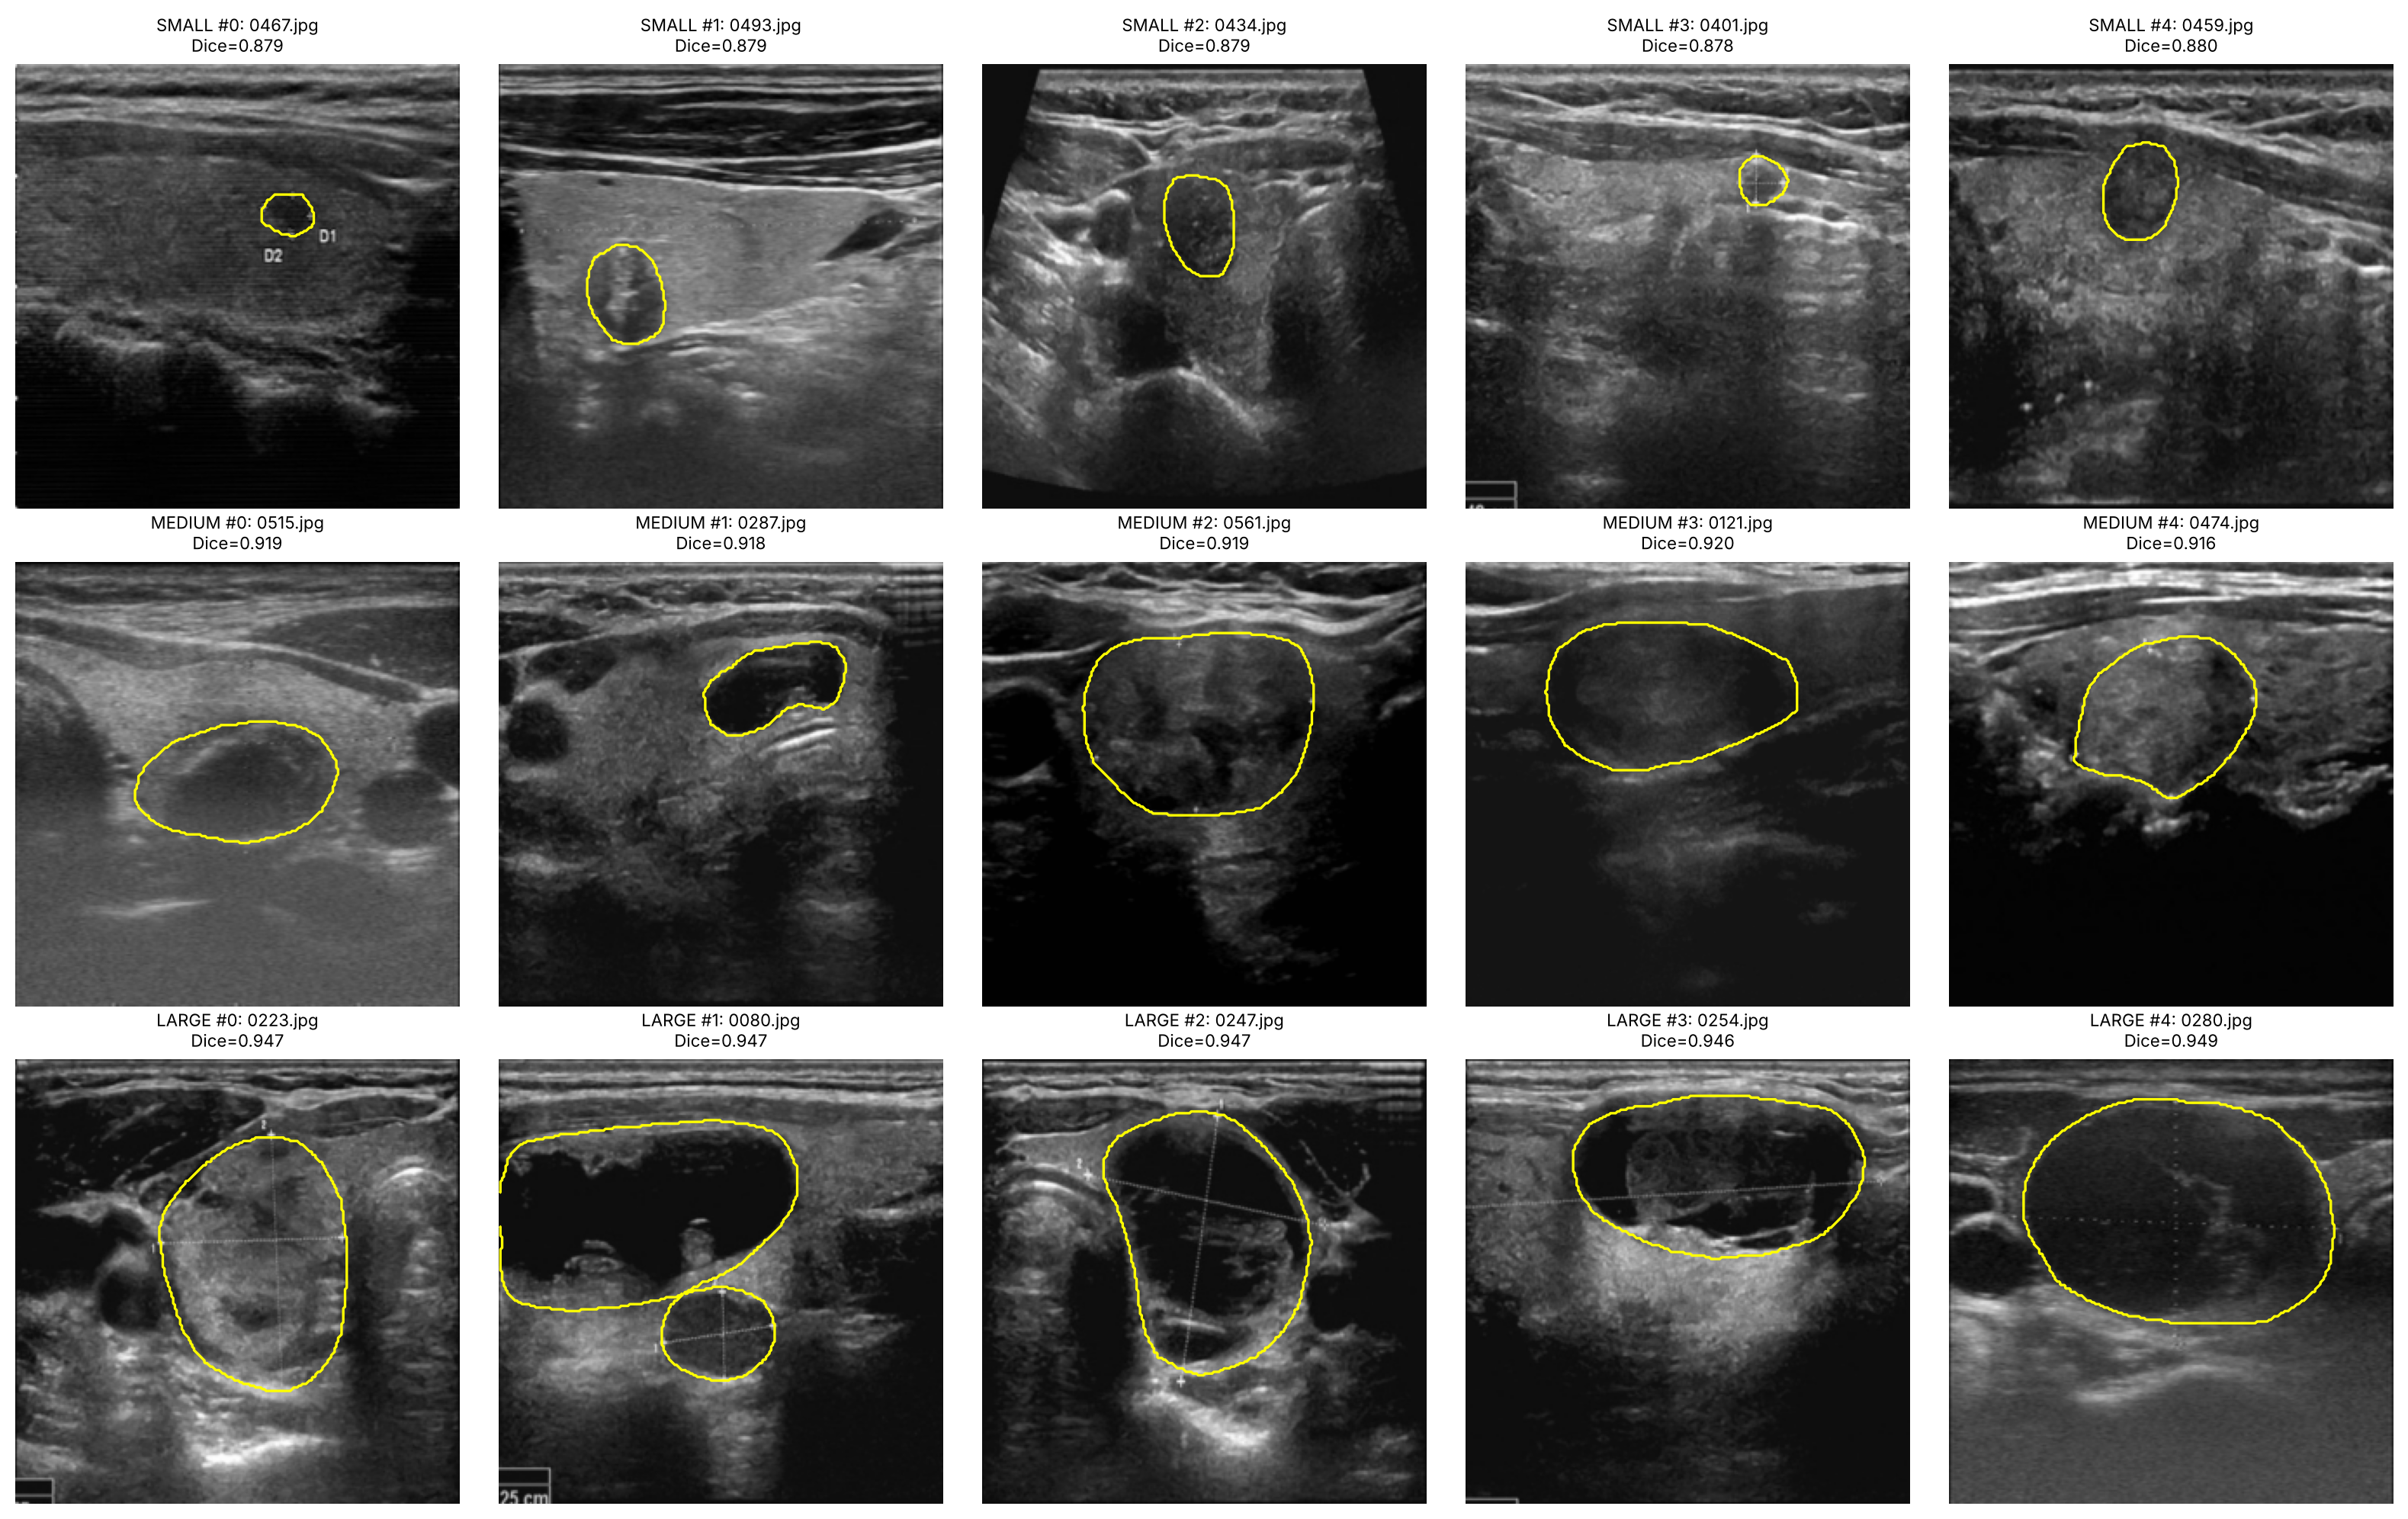

In [36]:
# --- 4) Gallery: N_CANDIDATES per stratum, to visually pick the most interesting one
fig, axes = plt.subplots(3, N_CANDIDATES, figsize=(3.2 * N_CANDIDATES, 10))
for g in range(3):
    for col, i in enumerate(candidates[g]):
        ax = axes[g, col]
        img = load_img(i)
        ax.imshow(img)
        ax.contour(masks[i], levels=[0.5], colors="yellow", linewidths=1.2)
        ax.set_title(f"{GROUP_NAMES[g]} #{col}: {names[i]}\nDice={dice_i[i]:.3f}", fontsize=8)
        ax.axis("off")
plt.tight_layout()
plt.show()

[('0493.jpg', 'SMALL', 0.879), ('0287.jpg', 'MEDIUM', 0.918), ('0080.jpg', 'LARGE', 0.947)]


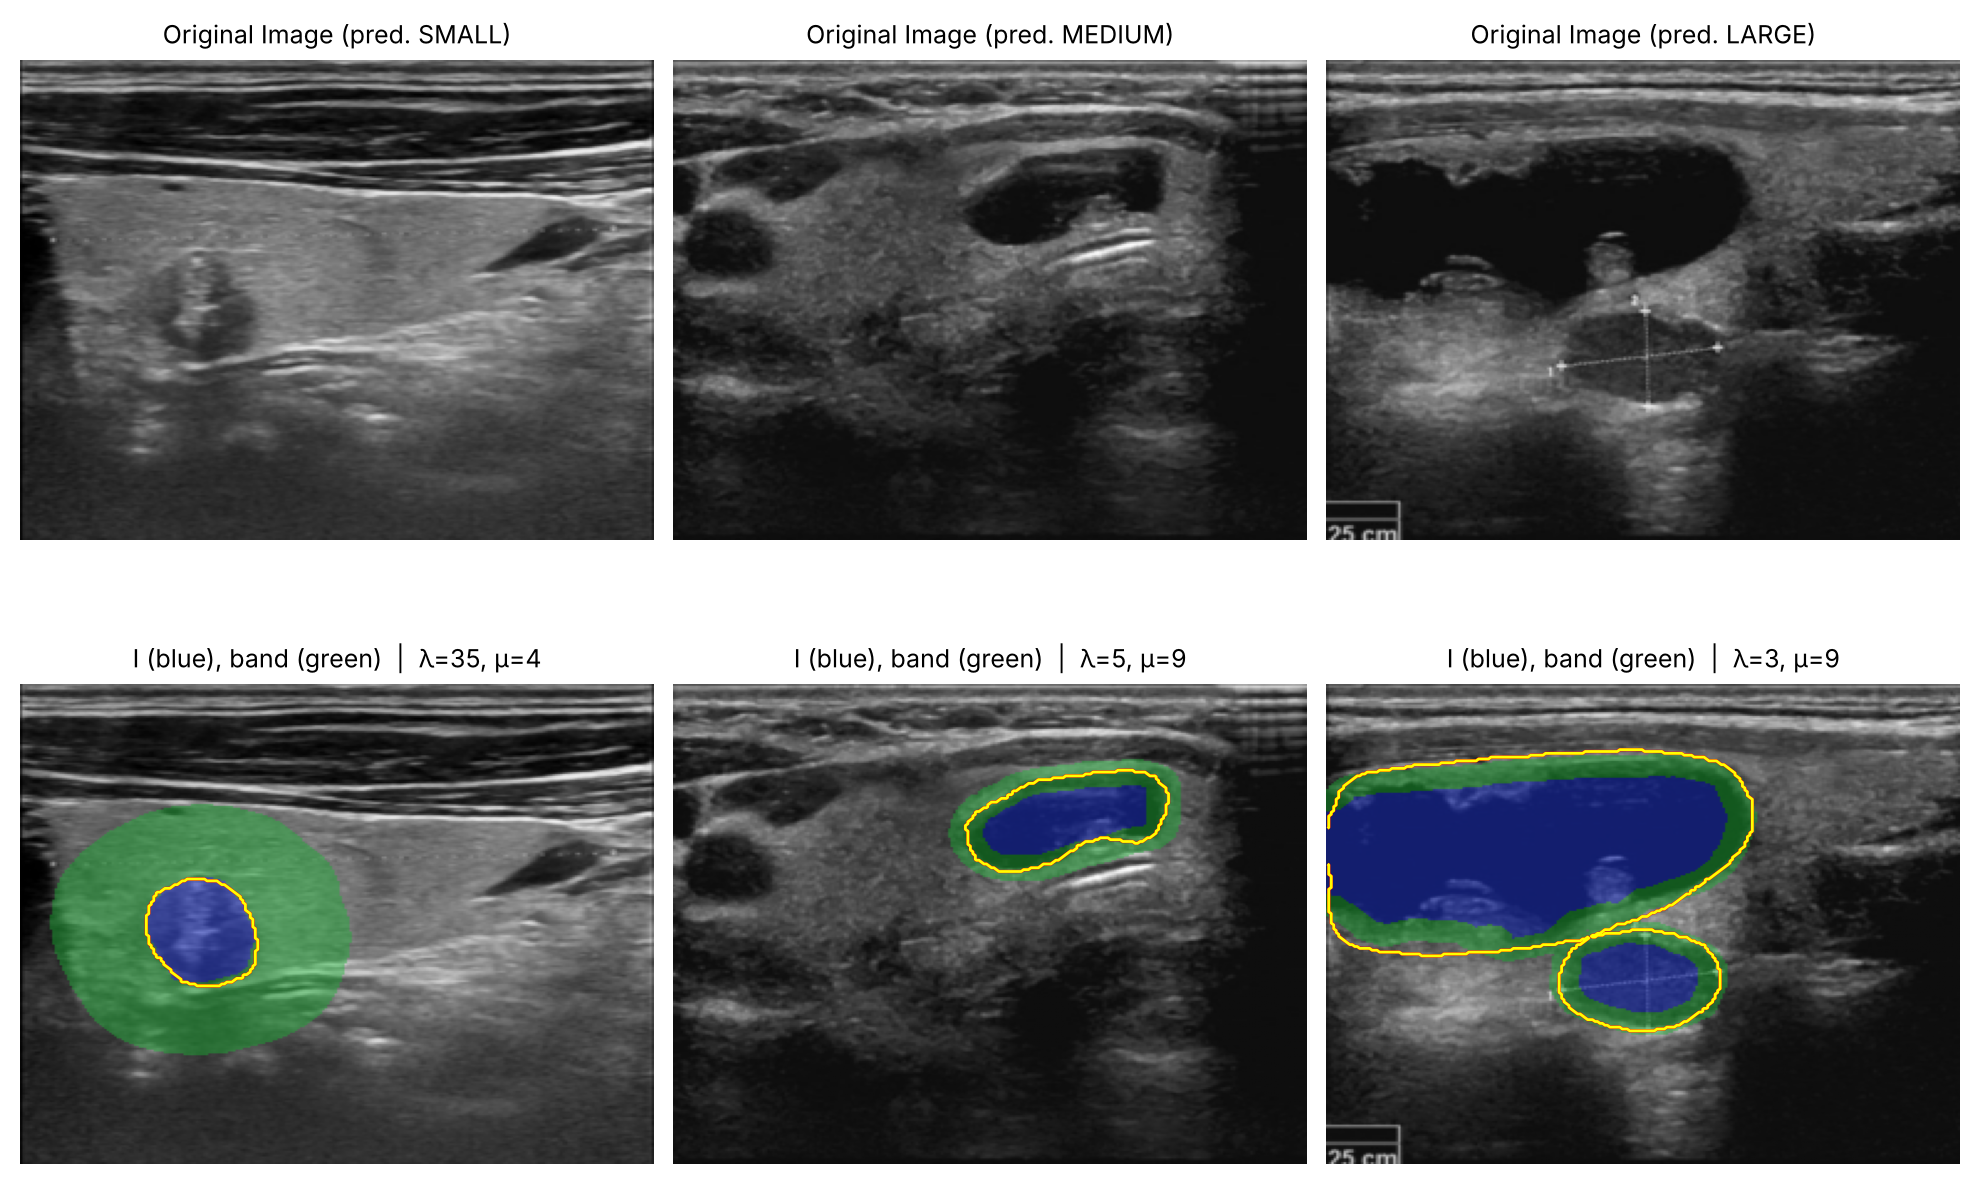

In [37]:
# --- 5) Manual pick: after looking at the gallery above, set which candidate (0 .. N_CANDIDATES-1) to use per stratum
SELECTED = {0: 1, 1: 1, 2: 1}
# To force a specific image instead, overwrite `cases` directly, e.g.:
# cases = [names.index("<file name>.jpg")]
cases = [candidates[g][SELECTED[g]] for g in range(3)]
print([(names[i], GROUP_NAMES[group_all[i]], round(float(dice_i[i]), 3)) for i in cases])

fig, axes = plt.subplots(2, len(cases), figsize=(3.3 * len(cases), 6))
axes = np.atleast_2d(axes)
for col, i in enumerate(cases):
    img = load_img(i)
    inner, band, g = bands(i)
    axes[0, col].imshow(img, aspect="auto")
    axes[0, col].set_title(f"Original Image (pred. {GROUP_NAMES[g]})", fontsize=9)
    axes[1, col].imshow(overlay(img, inner, band), aspect="auto")
    axes[1, col].contour(masks[i], levels=[0.5], colors="red", linewidths=1.2)   # GT in red, as in the paper's Fig. 2
    axes[1, col].contour(masks[i], levels=[0.5], colors="yellow", linewidths=1)
    axes[1, col].set_title(f"I (blue), band (green)  |  λ={lam_g[g]}, μ={mu_g[g]}", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
fig.subplots_adjust(left=0.01, right=0.99, top=0.93, bottom=0.01, wspace=0.03, hspace=0.3)
FIG_DIR.mkdir(exist_ok=True)
plt.savefig(FIG_DIR / "fig_bands_mondrian.pdf", bbox_inches="tight")
plt.savefig(FIG_DIR / "fig_bands_mondrian.png", dpi=200, bbox_inches="tight")
plt.show()